# Euler–Maruyama drift–diffusion

Euler–Maruyama combines an $O(\Delta t)$ drift increment with an
$O(\sqrt{\Delta t})$ Wiener increment. Matrix-valued simulations in one,
two, and three dimensions test the predicted mean and covariance.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Simulation

The same scalar diffusivity is applied through $\sqrt{2D}I_d$. Independent
normal vectors are generated for every path and time step.


In [2]:
rng = np.random.default_rng(62706)
diffusivity = 0.45
time_step = 0.01
step_count = 800
path_count = 12_000
shown_path_count = 8
maximum_drift = np.array([0.35, -0.20, 0.12])
time = time_step * np.arange(step_count + 1)
results = {}

for dimension in (1, 2, 3):
    drift = maximum_drift[:dimension]
    position = np.zeros((path_count, dimension))
    shown_paths = np.zeros((step_count + 1, shown_path_count, dimension))
    mean = np.zeros((step_count + 1, dimension))
    centered_msd = np.zeros(step_count + 1)

    for step in range(1, step_count + 1):
        normal_vector = rng.standard_normal((path_count, dimension))
        position += (
            drift * time_step
            + np.sqrt(2.0 * diffusivity * time_step) * normal_vector
        )
        shown_paths[step] = position[:shown_path_count]
        mean[step] = np.mean(position, axis=0)
        centered = position - drift * time[step]
        centered_msd[step] = np.mean(np.sum(centered**2, axis=1))

    results[dimension] = {
        "drift": drift,
        "paths": shown_paths,
        "mean": mean,
        "centered_msd": centered_msd,
        "covariance": np.cov(position, rowvar=False, ddof=0),
    }


## Verification

For constant drift, $\mathbb E[\mathbf R_t]=\mathbf b t$ and
$\operatorname{Cov}(\mathbf R_t)=2DtI_d$.


In [3]:
for dimension in (1, 2, 3):
    drift = results[dimension]["drift"]
    final_mean = results[dimension]["mean"][-1]
    covariance = np.atleast_2d(results[dimension]["covariance"])
    expected_covariance = 2.0 * diffusivity * time[-1] * np.eye(dimension)
    assert np.linalg.norm(final_mean - drift * time[-1]) < 0.12
    assert np.allclose(covariance, expected_covariance, rtol=0.05, atol=0.08)
    slope = np.polyfit(time[1:], results[dimension]["centered_msd"][1:], 1)[0]
    fitted_diffusivity = slope / (2.0 * dimension)
    assert np.isclose(fitted_diffusivity, diffusivity, rtol=0.04)
    print(f"{dimension}D fitted D = {fitted_diffusivity:.6f}")


1D fitted D = 0.457042
2D fitted D = 0.445764
3D fitted D = 0.455292


## Instructive plot

Dashed curves identify deterministic ensemble means. The centered MSD removes
those means and isolates diffusive spreading.


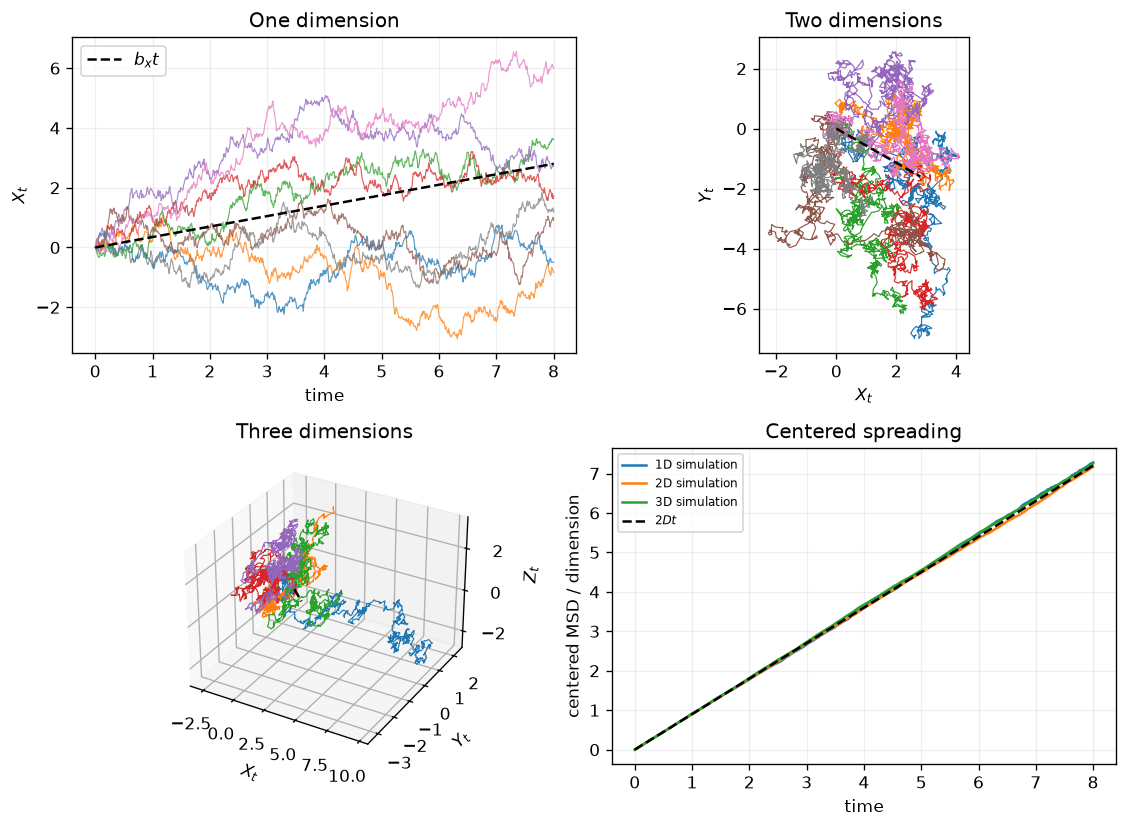

wrote lecture-notes/figures/08_brownian-motion-diffusion/06-euler-maruyama-drift-diffusion.pdf


In [4]:
figure = plt.figure(figsize=(9.5, 7.0))
axis_1d = figure.add_subplot(2, 2, 1)
axis_2d = figure.add_subplot(2, 2, 2)
axis_3d = figure.add_subplot(2, 2, 3, projection="3d")
axis_msd = figure.add_subplot(2, 2, 4)

axis_1d.plot(time, results[1]["paths"][:, :, 0], linewidth=0.7, alpha=0.75)
axis_1d.plot(time, maximum_drift[0] * time, "k--", label=r"$b_xt$")
axis_1d.set(title="One dimension", xlabel="time", ylabel=r"$X_t$")
axis_1d.legend()

paths_2d = results[2]["paths"]
for path_index in range(shown_path_count):
    axis_2d.plot(paths_2d[:, path_index, 0], paths_2d[:, path_index, 1], linewidth=0.7)
axis_2d.plot(maximum_drift[0] * time, maximum_drift[1] * time, "k--")
axis_2d.set(title="Two dimensions", xlabel=r"$X_t$", ylabel=r"$Y_t$")
axis_2d.set_aspect("equal", adjustable="box")

paths_3d = results[3]["paths"]
for path_index in range(5):
    axis_3d.plot(
        paths_3d[:, path_index, 0],
        paths_3d[:, path_index, 1],
        paths_3d[:, path_index, 2],
        linewidth=0.7,
    )
axis_3d.plot(
    maximum_drift[0] * time,
    maximum_drift[1] * time,
    maximum_drift[2] * time,
    "k--",
)
axis_3d.set(title="Three dimensions", xlabel=r"$X_t$", ylabel=r"$Y_t$", zlabel=r"$Z_t$")

for dimension in (1, 2, 3):
    axis_msd.plot(
        time,
        results[dimension]["centered_msd"] / dimension,
        label=f"{dimension}D simulation",
    )
axis_msd.plot(time, 2.0 * diffusivity * time, "k--", label=r"$2Dt$")
axis_msd.set(title="Centered spreading", xlabel="time", ylabel="centered MSD / dimension")
axis_msd.legend(fontsize=7)

for axis in (axis_1d, axis_2d, axis_msd):
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "06-euler-maruyama-drift-diffusion.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
